<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_Entrainer_un_CNN_sur_l%E2%80%99ASL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint: Entraîner un CNN sur l'alphabet ASL (langue des signes américaine)

**Objectif** : entraîner un petit réseau convolutionnel sur des photos de mains qui forment les lettres de l'alphabet ASL, puis diagnostiquer s'il est en **surapprentissage**, en **sous-apprentissage** ou s'il est bien ajusté.


## Étape 0 : imports et vérification du GPU

In [1]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)
print("GPU :", tf.config.list_physical_devices("GPU") or "aucun, l'entraînement sera lent")

TensorFlow 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Étape 1 : télécharger le jeu de données

`kagglehub`

In [2]:
import kagglehub
chemin = kagglehub.dataset_download("grassknoted/asl-alphabet")
print("Téléchargé dans :", chemin)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Téléchargé dans : /kaggle/input/asl-alphabet


In [3]:
def trouver_dossier(racine, nom):
    for d, sous_dossiers, _ in os.walk(racine):
        if os.path.basename(d) == nom and "A" in sous_dossiers:
            return d
    for d, _, fichiers in os.walk(racine):
        if os.path.basename(d) == nom and any(f.lower().endswith(".jpg") for f in fichiers):
            return d
    raise FileNotFoundError(nom)

dossier_train = trouver_dossier(chemin, "asl_alphabet_train")
classes = sorted(os.listdir(dossier_train))
print(len(classes), "classes :", classes)
print("Images par classe :", len(os.listdir(os.path.join(dossier_train, classes[0]))))

29 classes : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']
Images par classe : 3000


## Étape 2 : prétraitement

### 2.a Sous-échantillonner et séparer train / validation

La séparation se fait à 80 / 20 avec `stratify`. On répartit des **chemins de fichiers** : les images ne sont chargées qu'ensuite.

In [4]:
IMAGES_PAR_CLASSE = 1000

chemins, etiquettes = [], []
for i, c in enumerate(classes):
    fichiers = sorted(glob.glob(os.path.join(dossier_train, c, "*.jpg")))
    random.Random(42).shuffle(fichiers)
    fichiers = fichiers[:IMAGES_PAR_CLASSE]
    chemins += fichiers
    etiquettes += [i] * len(fichiers)

ch_train, ch_val, y_train, y_val = train_test_split(
    chemins, etiquettes, test_size=0.2, stratify=etiquettes, random_state=42
)
print("Entraînement :", len(ch_train), "| Validation :", len(ch_val))

Entraînement : 23200 | Validation : 5800


### 2.b Redimensionner et normaliser

Chaque image passe dans la même fonction :
- **redimensionnement** de 200×200 à **64×64**, ce qui divise par 10 le nombre de pixels à traiter ;
- **normalisation** des pixels de [0, 255] vers [0, 1] (division par 255).

In [5]:
TAILLE = 64
BATCH = 64

def charger(chemin, etiquette):
    img = tf.io.read_file(chemin)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (TAILLE, TAILLE))
    img = img / 255.0
    return img, etiquette

def construire(ch, y, melanger):
    ds = tf.data.Dataset.from_tensor_slices((ch, y))
    ds = ds.map(charger, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if melanger:
        ds = ds.shuffle(len(ch), seed=42)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

ds_train = construire(ch_train, y_train, melanger=True)
ds_val = construire(ch_val, y_val, melanger=False)

imgs, labs = next(iter(ds_train))
print("Forme d'un lot :", imgs.shape, "| pixels entre", float(tf.reduce_min(imgs)), "et", float(tf.reduce_max(imgs)))

Forme d'un lot : (64, 64, 64, 3) | pixels entre 0.0 et 1.0


### 2.c Visualiser quelques images

C'est le moment de vérifier que les étiquettes correspondent bien aux images.

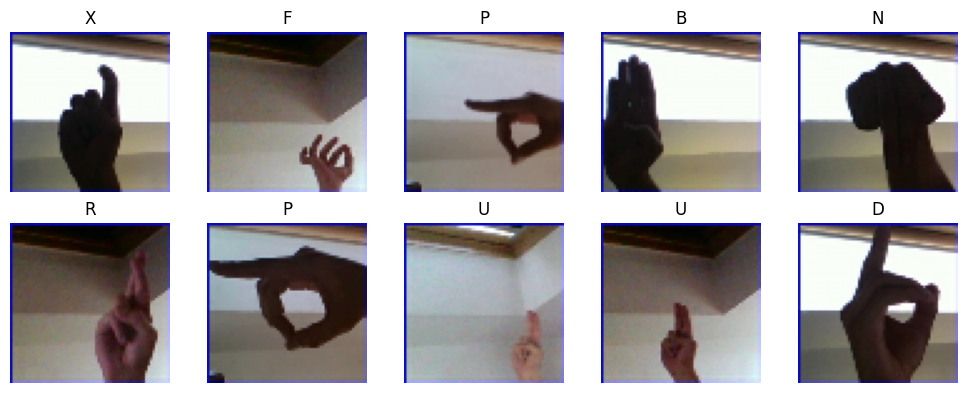

In [6]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(imgs[i].numpy())
    plt.title(classes[int(labs[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Étape 3 : construire le CNN

In [7]:
model = keras.Sequential([
    keras.Input(shape=(TAILLE, TAILLE, 3)),
    keras.layers.Conv2D(32, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(128, 3, activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(len(classes), activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 686,941 (2.62 MB)

 Trainable params: 686,941 (2.62 MB)

 Non-trainable params: 0 (0.00 B)

## Étape 4 : compiler et entraîner

n passe `validation_data` à `fit()` : à la fin de chaque époque, Keras mesure la perte et la précision sur les images de validation, sans entraîner le modèle dessus.

L'objet `historique` enregistre les quatre courbes demandées : `loss`, `accuracy`, `val_loss` et `val_accuracy`.

In [8]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

EPOQUES = 10
historique = model.fit(ds_train, validation_data=ds_val, epochs=EPOQUES)

Epoch 1/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 43s 88ms/step - accuracy: 0.4805 - loss: 1.7481 - val_accuracy: 0.7379 - val_loss: 0.8197
Epoch 2/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.8322 - loss: 0.5244 - val_accuracy: 0.8881 - val_loss: 0.3528
Epoch 3/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9198 - loss: 0.2508 - val_accuracy: 0.9290 - val_loss: 0.2121
Epoch 4/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9522 - loss: 0.1483 - val_accuracy: 0.9491 - val_loss: 0.1573
Epoch 5/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9688 - loss: 0.1001 - val_accuracy: 0.9526 - val_loss: 0.1511
Epoch 6/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9777 - loss: 0.0721 - val_accuracy: 0.9347 - val_loss: 0.1975
Epoch 7/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9756 - loss: 0.0778 - val_accuracy: 0.9640 - val_loss: 0.1185
Epoch 8/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9840 - loss: 0.0532 - val_acc

## Étape 5 : tracer les courbes

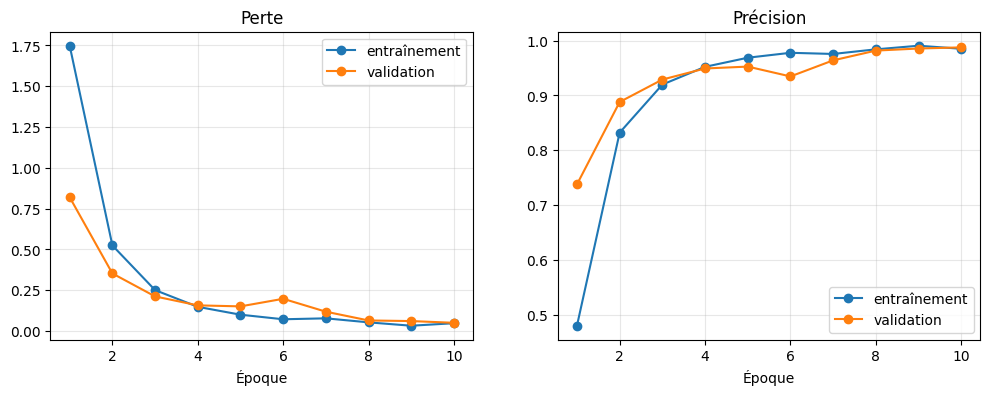

In [9]:
h = historique.history
ep = range(1, len(h["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, h["loss"], "o-", label="entraînement")
ax[0].plot(ep, h["val_loss"], "o-", label="validation")
ax[0].set_title("Perte")
ax[0].set_xlabel("Époque")
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(ep, h["accuracy"], "o-", label="entraînement")
ax[1].plot(ep, h["val_accuracy"], "o-", label="validation")
ax[1].set_title("Précision")
ax[1].set_xlabel("Époque")
ax[1].legend(); ax[1].grid(alpha=0.3)
plt.show()

## Étape 6 : analyser les performances

Cette cellule répond chiffres à l'appui aux deux questions de l'énoncé, puis propose un diagnostic.

Seuils utilisés (ce sont des repères, pas des règles absolues) :
- **écart de précision** entre train et validation supérieur à 5 points : signe de surapprentissage ;
- **perte de validation** finale supérieure de plus de 10 % à son minimum alors que la perte d'entraînement continue de baisser : surapprentissage ;
- précision **inférieure à 70 % sur les deux ensembles** : sous-apprentissage.

In [10]:
acc_tr, acc_va = h["accuracy"][-1], h["val_accuracy"][-1]
ecart = acc_tr - acc_va

vl = h["val_loss"]
ep_min = int(np.argmin(vl)) + 1
vl_remonte = vl[-1] > min(vl) * 1.10
tl_baisse = h["loss"][-1] < h["loss"][ep_min - 1]

print("Question 1 : la précision d'entraînement est-elle beaucoup plus élevée que celle de validation ?")
print(f"  train = {acc_tr:.2%} | validation = {acc_va:.2%} | écart = {ecart * 100:+.1f} points")
print("  ->", "OUI" if ecart > 0.05 else "NON", "\n")

print("Question 2 : la perte de validation augmente-t-elle alors que la perte d'entraînement diminue ?")
print(f"  val_loss minimale à l'époque {ep_min} ({min(vl):.4f}), finale = {vl[-1]:.4f}")
print(f"  perte d'entraînement : {h['loss'][ep_min - 1]:.4f} à l'époque {ep_min} -> {h['loss'][-1]:.4f} à la fin")
print("  ->", "OUI" if (vl_remonte and tl_baisse) else "NON", "\n")

if acc_tr < 0.70 and acc_va < 0.70:
    diag = "SOUS-APPRENTISSAGE : le modèle n'arrive même pas à bien classer les données d'entraînement."
elif ecart > 0.05 or (vl_remonte and tl_baisse):
    diag = "SURAPPRENTISSAGE : le modèle mémorise le train mais généralise moins bien."
else:
    diag = "BON AJUSTEMENT : les deux courbes progressent ensemble et restent proches."
print("Diagnostic :", diag)

Question 1 : la précision d'entraînement est-elle beaucoup plus élevée que celle de validation ?
  train = 98.50% | validation = 98.76% | écart = -0.3 points
  -> NON 

Question 2 : la perte de validation augmente-t-elle alors que la perte d'entraînement diminue ?
  val_loss minimale à l'époque 10 (0.0505), finale = 0.0505
  perte d'entraînement : 0.0480 à l'époque 10 -> 0.0480 à la fin
  -> NON 

Diagnostic : BON AJUSTEMENT : les deux courbes progressent ensemble et restent proches.


## Étape 7 : tester sur le dossier de test

In [11]:
dossier_test = trouver_dossier(chemin, "asl_alphabet_test")
fichiers_test = sorted(glob.glob(os.path.join(dossier_test, "*.jpg")))

corrects, total = 0, 0
for f in fichiers_test:
    vraie = os.path.basename(f).split("_test")[0]
    if vraie not in classes:
        continue
    img, _ = charger(f, 0)
    pred = classes[int(model.predict(img[None], verbose=0).argmax())]
    total += 1
    corrects += pred == vraie
    print(f"{vraie:<8} -> {pred:<8} {'ok' if pred == vraie else 'ERREUR'}")
print(f"\n{corrects}/{total} corrects")

A        -> A        ok
B        -> B        ok
C        -> C        ok
D        -> D        ok
E        -> E        ok
F        -> F        ok
G        -> G        ok
H        -> H        ok
I        -> I        ok
J        -> J        ok
K        -> K        ok
L        -> L        ok
M        -> M        ok
N        -> N        ok
O        -> O        ok
P        -> P        ok
Q        -> Q        ok
R        -> R        ok
S        -> S        ok
T        -> T        ok
U        -> U        ok
V        -> V        ok
W        -> W        ok
X        -> X        ok
Y        -> Y        ok
Z        -> Z        ok
nothing  -> nothing  ok
space    -> space    ok

28/28 corrects
